In [1]:
# Преоразовать существующий код для распознавания последовательности рукописных символов в текст.
# Написать генератор произвольной последовательности рукописных символов.

# ГЕНЕРАЦИЯ НАБОРА ДАННЫХ
# Сгенерировать набор текстовых строк из допустимых символов.
# Каждому набору поставить в соотвествие массив изоражений соответствующих символов.
# Добавить пробелы для разделения слов, символы пробелов не использовать во время классификации.

# КЛАССИФИКАЦИЯ (k ближайших соседей) (пример AIM practice 2)
# Часть символов оставить для обучения классификатора . Остальные  классифицировать
# по аналогии с примером mnist с прошлого занятия. Т.е. преобразовывать изображение в вектор.
# Выбрать оптимальный классификатор в зависимости от k- количество соседей.
# Метрика для измерения точности классификации, и выбора оптимального классификатора относительно параметра k - accuracy.

# РАСПОЗНАВАНИЕ
# заменить inf_net на последовательное применение следующих шагов:
# 1. генерация изображения с последовательностью символов
# 2. Выделение объектов оставляете как есть.
# 3. Примернить k-nn для решения задачи классификации. 
# 4. Вывести результат

In [2]:
import zipfile
import random
from pathlib import Path
from collections import defaultdict, Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)

ZIP_PATH = Path("data.zip")
if not ZIP_PATH.exists():
    raise FileNotFoundError(
        "Файл data.zip не найден."
    )

In [3]:
# Собираем пути изображений по классам.
paths_by_class = defaultdict(list)
with zipfile.ZipFile(ZIP_PATH) as archive:
    for name in archive.namelist():
        parts = name.strip("/").split("/")
        if name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")) and len(parts) >= 2:
            # Имя класса — папка непосредственно перед файлом.
            label = parts[-2]
            paths_by_class[label].append(name)

classes = sorted(paths_by_class)
print("Классы:", classes)
print("Всего изображений:", sum(map(len, paths_by_class.values())))
if len(classes) < 2:
    raise ValueError("Не найдены папки классов в архиве. Проверьте структуру data.zip.")

Классы: ['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'X', 'h', 't', 'times', 'w', 'y']
Всего изображений: 225312


In [4]:
SIZE = 32

def prepare_image(image, size=SIZE):
    # Приводим к оттенкам серого.
    if image.ndim == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image = image.astype(np.uint8)

    # Устанавливаем белые символы на чёрном фоне.
    # Для светлого фона сначала инвертируем изображение.
    if np.median(image) > 127:
        image = 255 - image

    # Бинаризация, удаление слабого шума.
    _, binary = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if np.count_nonzero(binary) == 0:
        return np.zeros((size, size), dtype=np.float32)

    # Обрезаем пустые поля, сохраняем пропорции и центрируем символ.
    ys, xs = np.where(binary > 0)
    crop = binary[ys.min():ys.max()+1, xs.min():xs.max()+1]
    h, w = crop.shape
    scale = (size - 8) / max(h, w)
    new_w = max(1, round(w * scale))
    new_h = max(1, round(h * scale))
    resized = cv2.resize(crop, (new_w, new_h), interpolation=cv2.INTER_AREA)

    canvas = np.zeros((size, size), dtype=np.uint8)
    x0 = (size - new_w) // 2
    y0 = (size - new_h) // 2
    canvas[y0:y0+new_h, x0:x0+new_w] = resized
    return canvas.astype(np.float32) / 255.0

def load_from_zip(archive, name):
    data = np.frombuffer(archive.read(name), dtype=np.uint8)
    return cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)

In [5]:
SAMPLES_PER_CLASS = 120
X_train, y_train, X_test, y_test = [], [], [], []
test_images_by_class = defaultdict(list)

with zipfile.ZipFile(ZIP_PATH) as archive:
    for label in classes:
        names = paths_by_class[label].copy()
        random.shuffle(names)
        prepared = []
        for name in names:
            im = load_from_zip(archive, name)
            if im is None:
                continue
            prepared.append(prepare_image(im))
            if len(prepared) >= SAMPLES_PER_CLASS:
                break
        if len(prepared) < 2:
            print("Пропущен класс (мало изображений):", label)
            continue
        split = min(len(prepared)-1, max(1, int(len(prepared)*0.75)))
        for im in prepared[:split]:
            X_train.append(im.reshape(-1))
            y_train.append(label)
        for im in prepared[split:]:
            X_test.append(im.reshape(-1))
            y_test.append(label)
            test_images_by_class[label].append(im)

X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)
y_train = np.asarray(y_train)
y_test = np.asarray(y_test)

print("Обучение:", X_train.shape)
print("Проверка:", X_test.shape)

Обучение: (1890, 1024)
Проверка: (630, 1024)


k = 1: accuracy = 0.5444 (54.4%)
k = 3: accuracy = 0.5365 (53.7%)
k = 5: accuracy = 0.5270 (52.7%)
k = 7: accuracy = 0.5143 (51.4%)
Оптимальное k: 1


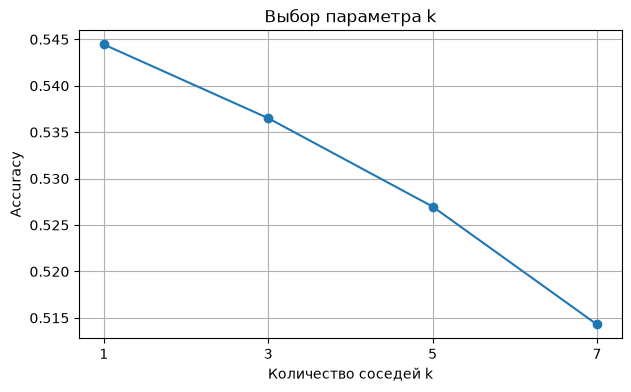

In [6]:
class SimpleKNN:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        self.X = np.asarray(X, dtype=np.float32)
        self.y = np.asarray(y)
        self.norms = np.sum(self.X * self.X, axis=1)
        return self

    def predict(self, X, batch_size=64):
        X = np.asarray(X, dtype=np.float32)
        if X.ndim == 1:
            X = X.reshape(1, -1)
        result = []
        for start in range(0, len(X), batch_size):
            batch = X[start:start+batch_size]
            d2 = np.maximum(
                np.sum(batch * batch, axis=1)[:, None]
                + self.norms[None, :]
                - 2 * (batch @ self.X.T), 0
            )
            nearest = np.argpartition(d2, self.k - 1, axis=1)[:, :self.k]
            for row, inds in enumerate(nearest):
                # Взвешенное голосование: более близкие соседи важнее.
                weights = 1.0 / (np.sqrt(d2[row, inds]) + 1e-5)
                scores = defaultdict(float)
                for label, weight in zip(self.y[inds], weights):
                    scores[str(label)] += float(weight)
                result.append(max(scores, key=scores.get))
        return np.asarray(result)

k_values = [1, 3, 5, 7]
accuracies = []
for k in k_values:
    model = SimpleKNN(k).fit(X_train, y_train)
    predictions = model.predict(X_test)
    acc = float(np.mean(predictions == y_test))
    accuracies.append(acc)
    print(f"k = {k}: accuracy = {acc:.4f} ({acc*100:.1f}%)")

best_k = k_values[int(np.argmax(accuracies))]
print("Оптимальное k:", best_k)

plt.figure(figsize=(7, 4))
plt.plot(k_values, accuracies, "o-")
plt.xticks(k_values)
plt.xlabel("Количество соседей k")
plt.ylabel("Accuracy")
plt.title("Выбор параметра k")
plt.grid(True)
plt.show()

knn = SimpleKNN(best_k).fit(X_train, y_train)

Исходный текст: 81+3 92


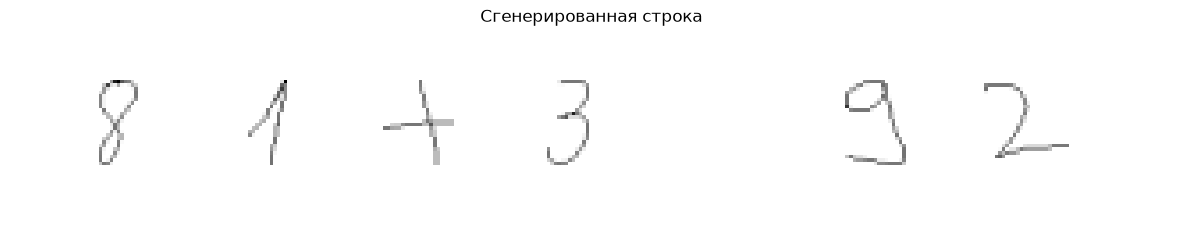

In [7]:
available = sorted(test_images_by_class)
digits = [c for c in "0123456789" if c in available]
symbols = [c for c in ["+", "-", "(", ")"] if c in available]

if len(digits) >= 3:
    true_tokens = [random.choice(digits), random.choice(digits),
                   random.choice(symbols or digits), random.choice(digits),
                   " ", random.choice(digits), random.choice(digits)]
else:
    true_tokens = [random.choice(available) for _ in range(4)] + [" "] + [random.choice(available) for _ in range(2)]
true_text = "".join(true_tokens)
normal_gap = 10
word_extra_gap = 45
margin = 15
line_parts = []
for token in true_tokens:
    if token == " ":
        line_parts.append(("space", word_extra_gap))
    else:
        glyph = (random.choice(test_images_by_class[token]) * 255).astype(np.uint8)
        line_parts.append((glyph, normal_gap))

width = 2 * margin + sum(gap if isinstance(item, str) else item.shape[1] + gap
                         for item, gap in line_parts)
line_image = np.full((SIZE + 20, width), 255, dtype=np.uint8)
cursor = margin
for item, gap in line_parts:
    if isinstance(item, str):
        cursor += gap
    else:
        h, w = item.shape
        line_image[10:10+h, cursor:cursor+w] = 255 - item
        cursor += w + gap

print("Исходный текст:", true_text)
plt.figure(figsize=(15, 3))
plt.imshow(line_image, cmap="gray", vmin=0, vmax=255)
plt.title("Сгенерированная строка")
plt.axis("off")
plt.show()

Выделено объектов: 6


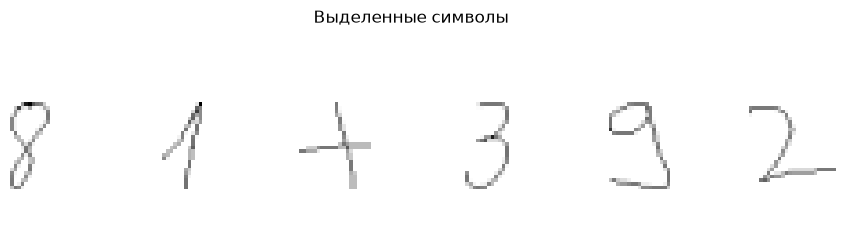

In [8]:
def segment_symbols(image):
    # Извлекаем диапазоны столбцов, в которых присутствует символ.
    binary = (image < 245).astype(np.uint8)
    occupied = np.flatnonzero(binary.sum(axis=0) > 0)
    if len(occupied) == 0:
        return []
    breaks = np.where(np.diff(occupied) > 1)[0]
    starts = np.r_[0, breaks + 1]
    ends = np.r_[breaks, len(occupied) - 1]
    segments = []
    for a, b in zip(starts, ends):
        x1, x2 = occupied[a], occupied[b] + 1
        patch = image[:, x1:x2]
        segments.append((int(x1), int(x2), patch))
    return segments

segments = segment_symbols(line_image)
print("Выделено объектов:", len(segments))

fig, axes = plt.subplots(1, max(1, len(segments)), figsize=(max(9, len(segments)*1.6), 2.5))
axes = np.atleast_1d(axes)
for ax, (_, _, patch) in zip(axes, segments):
    ax.imshow(patch, cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
for ax in axes[len(segments):]:
    ax.axis("off")
plt.suptitle("Выделенные символы")
plt.tight_layout()
plt.show()

In [9]:
if not segments:
    print("Символы не найдены.")
else:
    vectors = np.stack([prepare_image(patch).reshape(-1) for _, _, patch in segments])
    predicted = knn.predict(vectors)
    gaps = [segments[i][0] - segments[i-1][1] for i in range(1, len(segments))]
    space_threshold = 45
    recognized = str(predicted[0])
    for i in range(1, len(predicted)):
        if gaps[i-1] > space_threshold:
            recognized += " "
        recognized += str(predicted[i])
    print("Оригинал:   ", true_text)
    print("Распознано: ", recognized)
    print("Совпадение: ", recognized == true_text)
    print("Точность классификации на тесте:", round(max(accuracies)*100, 1), "%")

Оригинал:    81+3 92
Распознано:  81+3 92
Совпадение:  True
Точность классификации на тесте: 54.4 %
